
# Mini-Projet TP 2 :  Détection d'activités à partir d'accéléromètre (2ème partie)

## Nom de l'étudiant : RIPICEANU Denisa, KHOUJANE Nassim

Dans ce projet, vous prédirez 5 différentes activités humaines en utilisant des méthodes supervisées :

 **3-Debout, 4-Marcher,  5-Velo, 7-aspirateur_nettoyage et 8-Repassage**

en utilisant le capteur d'accéléromètre placé à deux endroits différents du corps :  torse et cheville.

Dans cette deuxième partie, pour réaliser cette classification, nous disposons de profils temporels des signaux extraites des accéléromètres. Les mesures respectivement en $ms^{-2}$  sont prélevées sur les 3-axes à une fréquence d'échantillonnage de 100Hz.
Les profils temporels comportent 128 pas de temps et chaque mesure est étiquetée.

Il est fourni pour ce capteur et chaque position, une matrice des mesures collectées avec l'étiquette de l'activité (c'est-à-dire la verité terrain).

Vous disposez des matrices suivantes
- **X_train_Torse_TP2.npy** et **X_test_Torse_TP2.npy** deux matrices d'apprentissage et de test de dimensions 384 (concatenation des signaux de 128 pas de temps sur les 3 axes X, Y et Z) du capteur d'accéléromètre situé sur le torse.
-  **X_train_Cheville_TP2.npy** et **X_test_Cheville_TP2.npy** deux matrices d'apprentissage et de test de dimensions 384 (concatenation des signaux de 128 pas de temps sur les 3 axes X, Y et Z) du capteur d'accéléromètre situé sur la cheville.
-  **LabelTrain_TP2.npy** et **LabelTest_TP2.npy** les vecteurs respectifs des labels pour la base d'apprentissage et de test dont le numéro correspond à une des 5 activités présentées ci-dessus.

In [ ]:
from google.colab import files

uploaded = files.upload()

Saving Xtrain_Torse_TSFEL_TP2.npy to Xtrain_Torse_TSFEL_TP2 (1).npy
Saving Xtest_Torse_TSFEL_TP2.npy to Xtest_Torse_TSFEL_TP2 (1).npy
Saving ListeVariableTemps.npy to ListeVariableTemps (1).npy
Saving ListeVariableStat.npy to ListeVariableStat (1).npy
Saving ListeVariableSpectral.npy to ListeVariableSpectral (1).npy
Saving LabelTrain_TP2.npy to LabelTrain_TP2 (1).npy
Saving LabelTest_TP2.npy to LabelTest_TP2 (1).npy


In [ ]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import math
from scipy import stats
from sklearn.naive_bayes import GaussianNB
from sklearn.metrics import accuracy_score, confusion_matrix
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans
from sklearn.neighbors import KNeighborsClassifier
from sklearn.cluster import AgglomerativeClustering
import seaborn as sns

# Chargement des données des capteurs placés sur le torse et la cheville

In [ ]:
# CAPTEUR TORSE
# Chargement des données d'apprentissage
Xtrain_Torse=np.load('./Xtrain_Torse_TSFEL_TP2.npy')
print('Taille de la base d apprentissage :', Xtrain_Torse.shape)

# Chargement des données de test
Xtest_Torse=np.load('./Xtest_Torse_TSFEL_TP2.npy')
print('Taille de la base de test :', Xtest_Torse.shape)


# LABELS
y_train=np.load('./LabelTrain_TP2.npy')
y_test=np.load('./LabelTest_TP2.npy')
print('Taille label apprentissage :',y_train.shape, 'Taille label test :',y_test.shape)

Taille de la base d apprentissage : (6031, 468)
Taille de la base de test : (2586, 468)
Taille label apprentissage : (6031,) Taille label test : (2586,)


### Fonctions pour réaliser une table de correspondance entre le label des approches non supervisées et le label réel

In [ ]:
def retrieve_info(cluster_labels,y_train):
 #Associe l'étiquette la plus probable à chaque groupe dans le modèle KMeans.
 #Résultats : dictionnaire des clusters associés à chaque étiquette.

# Initialisation
  reference_labels = np.zeros((len(np.unique(cluster_labels)),1))
# Loop pour chaque label
  for i in range(len(np.unique(cluster_labels))):
    index = np.where(cluster_labels == i,1,0)
    num = np.bincount(y_train[index==1]).argmax()
    reference_labels[i] = num
  return reference_labels

def correspondance(y_pred,label):
  # Correspondance entre la partition du clusterin y_pred et les classes de la vérité terrain label
  reference_labels = retrieve_info(y_pred,label)
  number_labels = np.zeros(len(y_pred))
  for i in range(len(y_pred)):
    number_labels[i] = reference_labels[y_pred[i]]
  return number_labels

# Partie I : Classification des activités sans prétraitement

Réaliser une classification des activités par deux méthodes d'apprentissage supervisé  de votre choix en utilisant les codes des TP précédents.


## Méthodes supervisées  :
Indiquer quelle est la méthode supervisée et les paramètres utilisées.  Calculer la matrice de confusion associée, le pourcentage de bonne classification et commentez les résultats.

Score de performance : 0.8553750966744006
Score de performance Base d Apprentissage : 0.8530923561598408


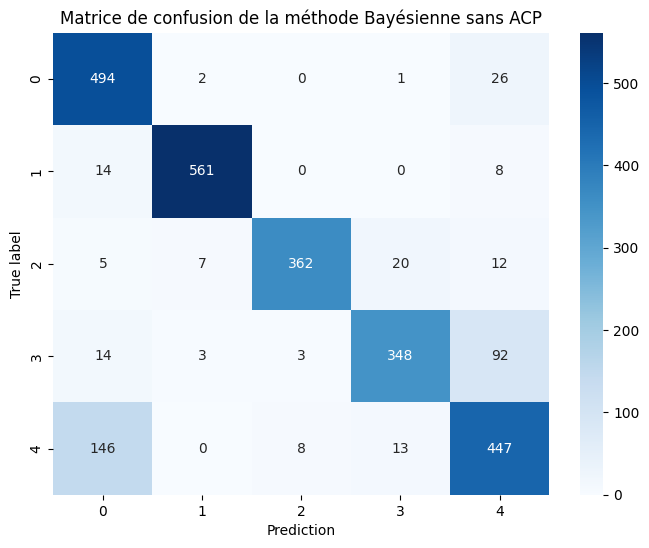

In [ ]:
# Classification bayésienne

# chargement du modèle et de ses paramètres
clf = GaussianNB()
# Apprentissage du modèle et de ses paramètres à l'aide des données étiquettées,
# c'est-à-dire de la base d'apprentissage, X_train et de ses labels y_train
clf.fit(Xtrain_Torse, y_train)

# Evaluation
# Calcul de la matrice de confusion et du pourcentage de bonne classification

# Une fois le modèle appris, on teste ce modèle sur un nouveau jeu de données X_test
y_pred_Bayes=clf.predict(Xtest_Torse)

# Evaluation de la performance du modèle à l'aide de la vérité terrain y_test
print('Score de performance :',accuracy_score(y_test, y_pred_Bayes))

# Evaluation du modèle appris sur la base d'apprentissage
y_pred_train_Bayes=clf.predict(Xtrain_Torse)

print('Score de performance Base d Apprentissage :',accuracy_score(y_train, y_pred_train_Bayes))

matrice = confusion_matrix(y_test, y_pred_Bayes)

plt.figure(figsize=(8, 6))
sns.heatmap(matrice, annot=True, fmt='d', cmap='Blues')
plt.title('Matrice de confusion de la méthode Bayésienne sans ACP')
plt.xlabel('Prediction')
plt.ylabel('True label')
plt.show()

D'un côté, les classes 0 et 1 correspondant aux activités Debout et Marcher sont quasi parfaites. La diagonale est bien définie et il y a très peu d'erreurs car ce sont des postures très distinctes et faciles à identifier.

Par contre, la tâche se complique pour les classes 2, 3 et 4 comme le Vélo, l'Aspirateur/Nettoyage et le Repassage. On voit pas mal de confusions entre ces groupes. C'est logique car avec un seul capteur fixé sur le torse, la position du haut du corps reste assez similaire pour ces activités. Cela piège l'algorithme qui a du mal à les différencier.

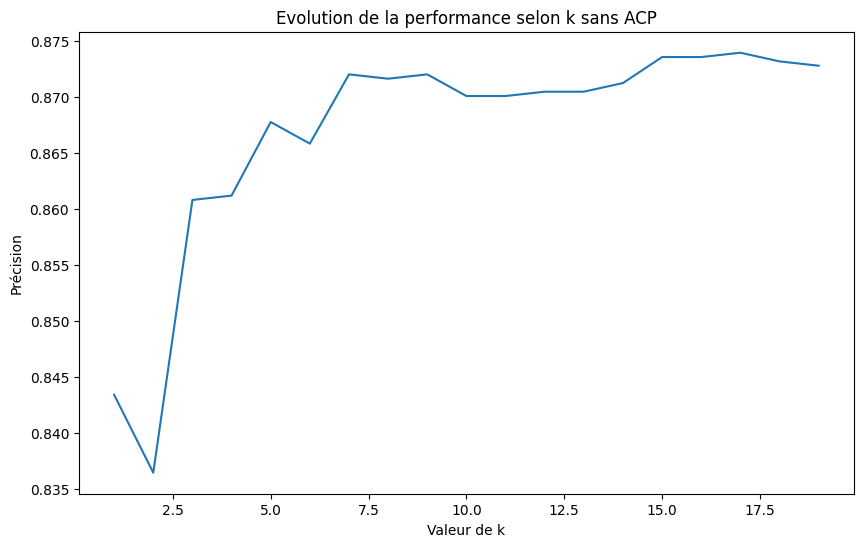

17


In [ ]:
# Combien de K pour Nearest neighbors ?

# On construit le graphique de score précision en fonction de k entre 0 et 19
scores = []
for k in range(1, 20):
    knn = KNeighborsClassifier(n_neighbors=k)
    knn.fit(Xtrain_Torse, y_train)
    scores.append(knn.score(Xtest_Torse, y_test))

plt.figure(figsize=(10, 6))
plt.plot(range(1, 20), scores)
plt.xlabel('Valeur de k')
plt.ylabel('Précision')
plt.title('Evolution de la performance selon k sans ACP')
plt.show()

# Quel k a donné le score le plus haut ?
print(range(1,20)[np.argmax(scores)]) # On choisit 17

Ce graphique permet de justifier le choix de notre paramètre k.

Au début de la courbe, pour les petites valeurs comme k=1 ou k=2, on voit que la précision est plus faible et assez instable avec des pics vers le bas. Le modèle est alors trop sensible au bruit et aux erreurs locales.

Ensuite, la performance grimpe rapidement avant de se stabiliser. On atteint le score maximal de précision pour k=17. C'est donc cette valeur que nous avons retenue pour la suite car elle offre le meilleur résultat : le modèle consulte assez de voisins pour être robuste sans trop lisser l'information.

Score de performance : 87.39365815931941 %
Score de performance Base d Apprentissage : 88.12800530591942 %


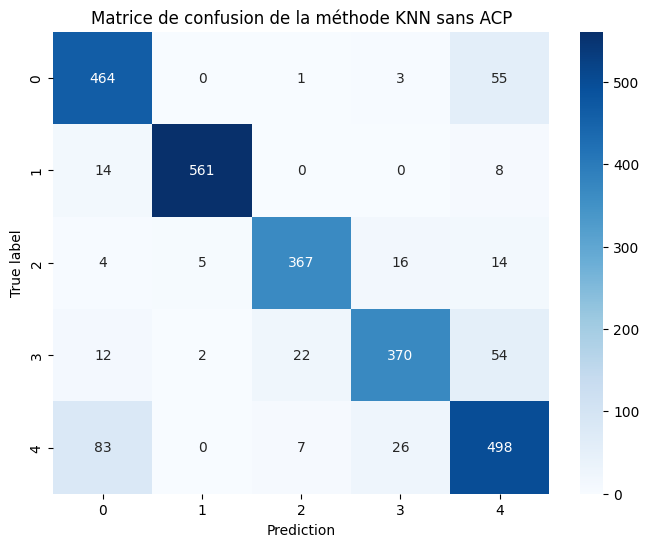

In [ ]:
# Nearest neighbors
neigh = KNeighborsClassifier(n_neighbors=17)
neigh.fit(Xtrain_Torse, y_train)
y_pred_KNN = neigh.predict(Xtest_Torse)
y_pred_train_KNN = neigh.predict(Xtrain_Torse)

# Evaluation de la performance du modèle à l'aide de la vérité terrain y_test
print('Score de performance :',accuracy_score(y_test, y_pred_KNN)*100, '%')

print('Score de performance Base d Apprentissage :',accuracy_score(y_train, y_pred_train_KNN)*100, '%')

matrice = confusion_matrix(y_test, y_pred_KNN)

plt.figure(figsize=(8, 6))
sns.heatmap(matrice, annot=True, fmt='d', cmap='Blues')
plt.title('Matrice de confusion de la méthode KNN sans ACP')
plt.xlabel('Prediction')
plt.ylabel('True label')
plt.show()

Comme avec la méthode précédente, les classes Debout et Marcher sont reconnues avec une très grande précision et quasiment aucune erreur.

On retrouve encore des confusions entre le Vélo, l'Aspirateur/Nettoyage et le Repassage, mais elles sont moins nombreuses qu'avec la méthode bayésienne. Cela montre que le KNN arrive mieux à saisir les détails de ces mouvements complexes là où le Bayésien avait plus de mal.

### Méthode non supervisée

In [ ]:
# on combine les données d'entraînement et de test (on les met bout à bout)
Data=np.concatenate([Xtrain_Torse,Xtest_Torse],axis=0)
print(Data.shape) # taille des données combinées

# on combine les labels d'entraînement et de test
Label=np.concatenate([y_train,y_test],axis=0)
print(Label.shape) # taille des étiquettes combinées

(8617, 468)
(8617,)


#### Classification par K-means

Partition retournée [5. 4. 5. ... 5. 3. 3.]
Score de performance : 72.83277242659858 %


/tmp/ipython-input-3587745824.py:19: DeprecationWarning: Conversion of an array with ndim > 0 to a scalar is deprecated, and will error in future. Ensure you extract a single element from your array before performing this operation. (Deprecated NumPy 1.25.)
  number_labels[i] = reference_labels[y_pred[i]]


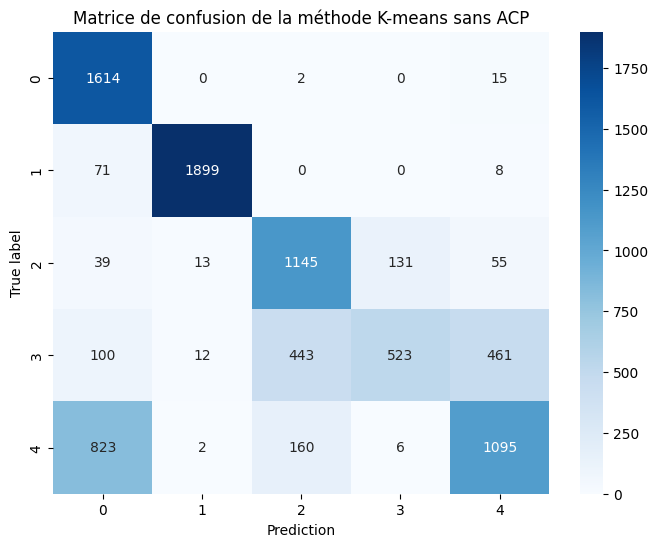

In [ ]:
# Classification K-means

y_pred_KM = KMeans(n_clusters=5, init='random').fit_predict(Data)
y_pred_KM = correspondance(y_pred_KM,Label)

print('Partition retournée',y_pred_KM)

print('Score de performance :',accuracy_score(Label, y_pred_KM)*100, '%')

matrice = confusion_matrix(Label, y_pred_KM)

plt.figure(figsize=(8, 6))
sns.heatmap(matrice, annot=True, fmt='d', cmap='Blues')
plt.title('Matrice de confusion de la méthode K-means sans ACP')
plt.xlabel('Prediction')
plt.ylabel('True label')
plt.show()

La classe Debout est très bien identifiée et la grande majorité des points se retrouve dans le bon cluster. La classe Marcher est elle aussi bien isolée du reste.

C'est beaucoup plus brouillon pour les autres activités. Les clusters correspondant au Vélo, à l'Aspirateur/Nettoyage et au Repassage sont très mélangés. On le voit bien avec la classe 4 où une grosse partie des points est classée par erreur dans le cluster 0 avec 823 points, au lieu d'aller dans le cluster 4 qui en contient 1095. Cela confirme que sans la supervision des étiquettes, l'algorithme K-means n'arrive pas à séparer ces activités dont les mouvements sont trop similaires.

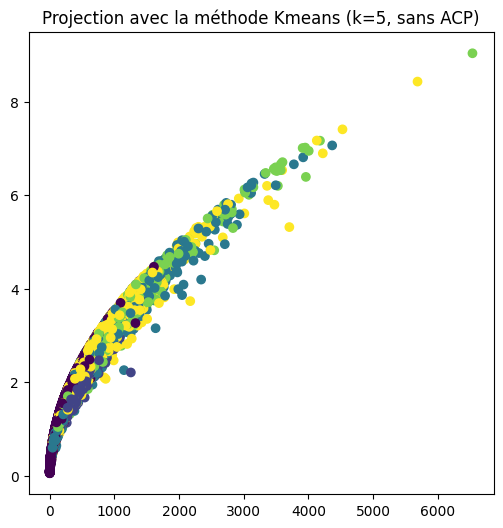

In [ ]:
plt.figure(figsize=(6, 6))
plt.scatter(Data[:, 0], Data[:, 1], c=y_pred_KM)
plt.title("Projection avec la méthode Kmeans (k=5, sans ACP)")
plt.show()

Le graphique montre que les données forment une courbe continue plutôt que des groupes bien séparés. Comme nous l'avons vu en cours, l'algorithme K-Means cherche naturellement des formes "rondes".

Ici, la forme allongée des données pose problème : l'algorithme est obligé de couper arbitrairement au milieu du nuage de points. C'est ce qui explique pourquoi les clusters se mélangent au centre : K-Means n'est pas l'outil idéal pour distinguer parfaitement ces activités qui se ressemblent trop.

Partition retournée [5. 4. 5. ... 5. 3. 3.]
Score de performance : 71.79993037019845 %


/tmp/ipython-input-3587745824.py:19: DeprecationWarning: Conversion of an array with ndim > 0 to a scalar is deprecated, and will error in future. Ensure you extract a single element from your array before performing this operation. (Deprecated NumPy 1.25.)
  number_labels[i] = reference_labels[y_pred[i]]


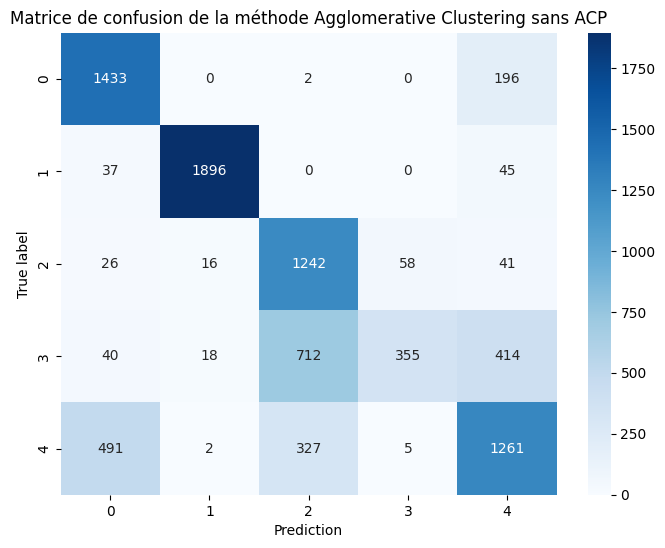

In [ ]:
# Agglomerative clustering

clustering = AgglomerativeClustering(n_clusters=5)
y_pred_AC = clustering.fit_predict(Data)
y_pred_AC = correspondance(y_pred_AC,Label)

print('Partition retournée',y_pred_AC)

print('Score de performance :',accuracy_score(Label, y_pred_AC)*100, '%')

matrice = confusion_matrix(Label, y_pred_AC)

plt.figure(figsize=(8, 6))
sns.heatmap(matrice, annot=True, fmt='d', cmap='Blues')
plt.title('Matrice de confusion de la méthode Agglomerative Clustering sans ACP')
plt.xlabel('Prediction')
plt.ylabel('True label')
plt.show()

La classe 0 et la classe 1 sont très bien identifiées
Par contre, il y a beaucoup de confusion pour les classes 2, 3 et 4. Par exemple, la classe 4 est souvent confondue avec la classe 0 et la classe 2 avec la classe 3.

 L'Agglomerative Clustering nous confirme donc la tendance vue avec le K-Means, que les méthodes non supervisées arrivent à distinguer les activités très différentes, comme être debout, mais peinent à séparer les activités qui se ressemblent sans l'aide des étiquettes.

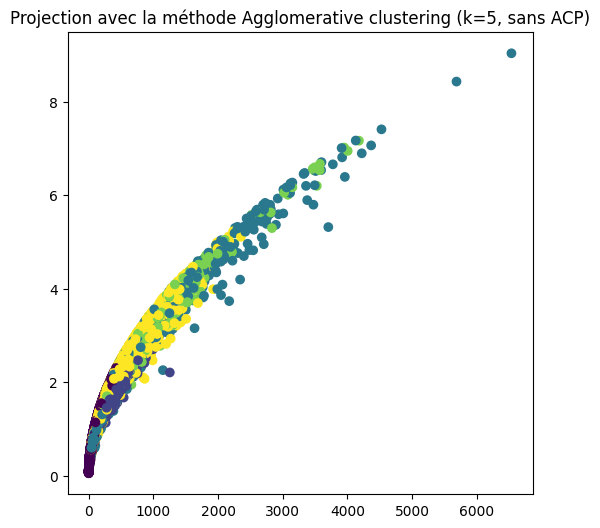

In [ ]:
plt.figure(figsize=(6, 6))
plt.scatter(Data[:, 0], Data[:, 1], c=y_pred_AC)
plt.title("Projection avec la méthode Agglomerative clustering (k=5, sans ACP)")
plt.show()

Comme pour le K-Means, on retrouve cette forme globale en "virgule".

Les couleurs montrent que le découpage est légèrement différent, surtout dans les zones de mélange au milieu.

Ici, l'algorithme a essayé de regrouper les points voisins (de proche en proche). Mais comme les données forment une suite continue sans "trou" ni cassure nette, la séparation reste difficile et la frontière que l'algorithme dessine entre les groupes est forcément un peu arbitraire.

## Commentaires sur les méthodes supervisées utilisées et les résultats suivant les capteurs :

La classification bayésienne atteint un score de 85.5%. Cette méthode, qui s'appuie sur des densités de probabilités, fait preuve d'une grande stabilité puisque le score sur la base d'apprentissage 85.3% est quasi identique à celui du test. Cela démontre que le modèle a réussi à capturer la distribution générale des données sans se focaliser sur des détails.

De son côté, l'algorithme des K-Plus Proches Voisins (avec k=17) se révèle être le modèle le plus performant avec 87.4% de réussite en test. En choisissant un k plus élevé (17 au lieu de 3 par exemple), nous avons lissé la frontière de décision. Cela se voit dans les résultats : l'écart entre le score d'apprentissage 88.1% et le score de test est désormais très faible (moins de 1%). Le modèle généralise donc excellemment bien et ne souffre pas de sur-apprentissage.

Pour conclure, les données issues du capteur Torse sont très discriminantes. Le KNN (k=17) est la méthode la plus robuste et précise pour séparer les différentes classes d'activités.

# Partie II : Classification des activités avec prétraitement

- Réalisez maintenant une réduction de dimension par ACP. Expliquez quelle est la dimension la + intéressante.
- Appliquez les mêmes méthodes supervisées réalisées en TP et commentez les paramètres choisis.
- Commentez les résultats.

## Réduction de dimension par Analyse en Composantes Principales (ACP)

Réaliser une ACP pour réduire la dimension et visualiser les données. Discuter sur le choix de la dimension.

On choisira 3 composantes principales pour l'entraînement de nos modèles. Ce choix nous permet de réduire la complexité du problème en réduisant le nombre de variables, tout en conservant 99% de la variance du signal original, on minimise alors la perte d'information utile.

1  components : variance cumulée =  0.6943043020226477
2  components : variance cumulée =  0.9370094124370233
3  components : variance cumulée =  0.9957069381563288
4  components : variance cumulée =  0.9990148846530663
5  components : variance cumulée =  0.9996651479199298
6  components : variance cumulée =  0.999807954673064
7  components : variance cumulée =  0.9998332448839871
8  components : variance cumulée =  0.9998503954962598
9  components : variance cumulée =  0.9998620816975186
10  components : variance cumulée =  0.9998731668204028
11  components : variance cumulée =  0.9998834908143032
12  components : variance cumulée =  0.9998933066991494
13  components : variance cumulée =  0.99990256626382
14  components : variance cumulée =  0.9999116115077926
15  components : variance cumulée =  0.9999199113535139
16  components : variance cumulée =  0.9999276422437482
17  components : variance cumulée =  0.9999347843127132
18  components : variance cumulée =  0.9999418912836787
19  

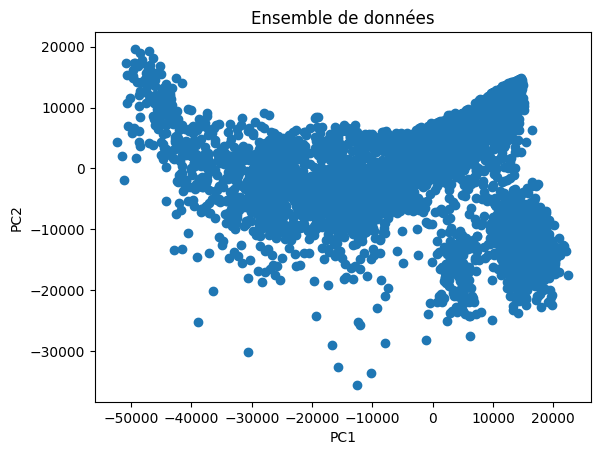

In [ ]:
# Cherche le nombre de components

pca = PCA()
pca.fit(Xtrain_Torse)
ratios = pca.explained_variance_ratio_
somme = 0
for i in range(20):
  somme += ratios[i]
  print(i+1, " components : variance cumulée = ", somme)

# 3 c'est le mieux
n_components=3
pca = PCA(n_components)
principalComponents = pca.fit_transform(Xtrain_Torse)

# affichage des points
plt.scatter(principalComponents[:, 0], principalComponents[:, 1],marker='o')
plt.title("Ensemble de données")
plt.xlabel("PC1")
plt.ylabel("PC2");
plt.show()

On constate que l'ACP a réussi à "déplier" l'espace complexe des 468 variables sur un plan 2D compréhensible. La forme courbe obtenue confirme que la relation entre les mesures des capteurs n'est pas simple, mais elle permet de visualiser clairement comment les données se structurent.

## méthodes supervisées avec réduction de dimension par ACP sur l'ensemble d'apprentissage
Après avoir réalisé une ACP sur l'ensemble d'apprentissage pour réduire la dimension
puis projeter les données de l'ensemble de test dans la base de l'ACP, appliquez les deux méthodes supervisées.



In [ ]:
# ACP
n_components=3
pca = PCA(n_components)
Xtrain_Torse_pca = pca.fit_transform(Xtrain_Torse)
Xtest_Torse_pca = pca.transform(Xtest_Torse)

print(Xtrain_Torse.shape, Xtest_Torse.shape)
print(Xtrain_Torse_pca.shape, Xtest_Torse_pca.shape)

(6031, 468) (2586, 468)
(6031, 3) (2586, 3)


Score de performance : 85.18948182521268 %
Score de performance Base d Apprentissage : 84.66257668711657 %


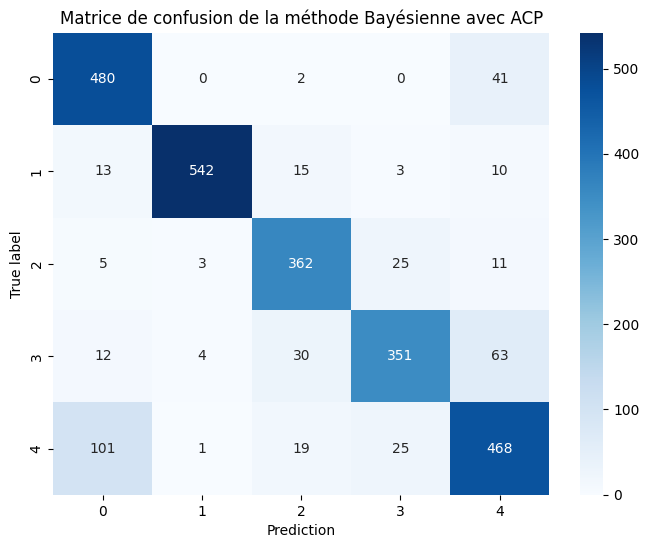

In [ ]:
# Classification bayésienne avec ACP

# chargement du modèle et de ses paramètres
clf = GaussianNB()
# Apprentissage du modèle et de ses paramètres à l'aide des données étiquettées,
# c'est-à-dire de la base d'apprentissage, X_train et de ses labels y_train
clf.fit(Xtrain_Torse_pca, y_train)

# Evaluation
# Calcul de la matrice de confusion et du pourcentage de bonne classification

# Une fois le modèle appris, on teste ce modèle sur un nouveau jeu de données X_test
y_pred_Bayes=clf.predict(Xtest_Torse_pca)

# Evaluation de la performance du modèle à l'aide de la vérité terrain y_test
print('Score de performance :',accuracy_score(y_test, y_pred_Bayes)*100, '%')

# Evaluation du modèle appris sur la base d'apprentissage
y_pred_train_Bayes=clf.predict(Xtrain_Torse_pca)

print('Score de performance Base d Apprentissage :',accuracy_score(y_train, y_pred_train_Bayes)*100, '%')

matrice = confusion_matrix(y_test, y_pred_Bayes)

plt.figure(figsize=(8, 6))
sns.heatmap(matrice, annot=True, fmt='d', cmap='Blues')
plt.title('Matrice de confusion de la méthode Bayésienne avec ACP')
plt.xlabel('Prediction')
plt.ylabel('True label')
plt.show()

Le score est quasi identique à celui obtenu sans ACP avec une précision de 85.2%. Cela montre que la réduction drastique de 468 à 3 variables a permis de conserver toute l'information nécessaire pour la classification.

Le score sur la base d'apprentissage atteint 84.7%, ce qui est très proche du score de test. Cela confirme que le modèle ne fait pas de sur-apprentissage et généralise bien, même avec des données compressées.

On retrouve les mêmes logiques que précédemment. Les classes 0 et 1 sont très bien reconnues, tandis que les confusions persistent entre les classes 2, 3 et 4 qui correspondent à des activités plus similaires.

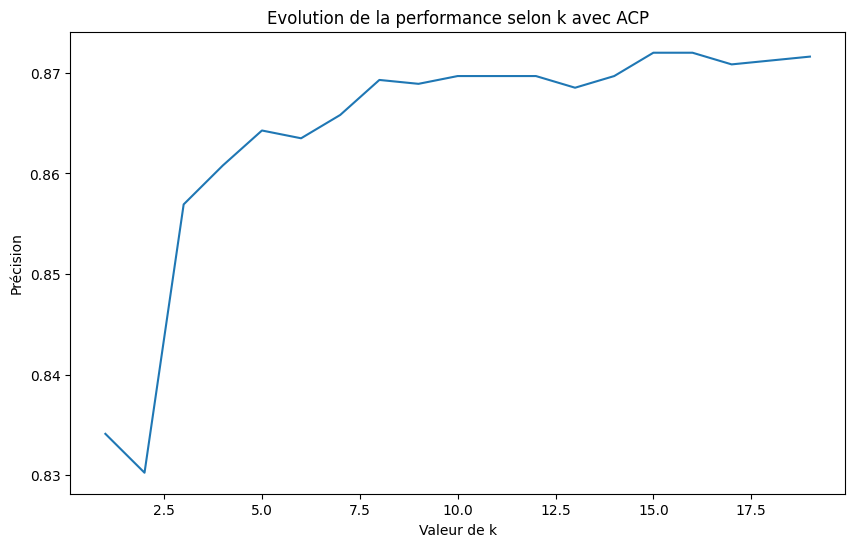

15


In [ ]:
# Combien de K pour Nearest neighbors ?

# On construit le graphique de score précision en fonction de k entre 0 et 19
scores = []
for k in range(1, 20):
    knn = KNeighborsClassifier(n_neighbors=k)
    knn.fit(Xtrain_Torse_pca, y_train)
    scores.append(knn.score(Xtest_Torse_pca, y_test))

plt.figure(figsize=(10, 6))
plt.plot(range(1, 20), scores)
plt.xlabel('Valeur de k')
plt.ylabel('Précision')
plt.title('Evolution de la performance selon k avec ACP')
plt.show()

# Quel k a donné le score le plus haut ?
print(range(1,20)[np.argmax(scores)]) # On choisit 15

Ce graphique montre l'évolution de la précision après avoir appliqué l'ACP.

On retrouve la même tendance globale avec une montée rapide des performances dès que l'on augmente le nombre de voisins. Cependant, on remarque que le sommet de la courbe est atteint un peu plus tôt, autour de k=15.

Nous avons donc retenu cette valeur de 15 pour notre modèle final. Ce léger décalage par rapport à 17 s'explique très bien. Comme l'ACP a déjà nettoyé les données en supprimant le bruit et les variables inutiles, l'algorithme a besoin de consulter un peu moins de voisins pour être sûr de sa décision.

Score de performance : 87.20030935808198 %
Score de performance Base d Apprentissage : 88.04510031503897 %


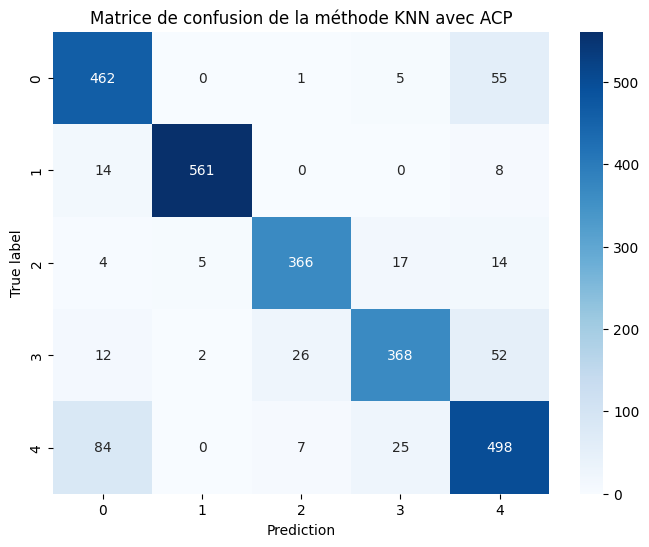

In [ ]:
# Nearest neighbors avec ACP
neigh = KNeighborsClassifier(n_neighbors=15)
neigh.fit(Xtrain_Torse_pca, y_train)
y_pred_KNN = neigh.predict(Xtest_Torse_pca)
y_pred_train_KNN = neigh.predict(Xtrain_Torse_pca)

# Evaluation de la performance du modèle à l'aide de la vérité terrain y_test
print('Score de performance :',accuracy_score(y_test, y_pred_KNN)*100, '%')

print('Score de performance Base d Apprentissage :',accuracy_score(y_train, y_pred_train_KNN)*100, '%')

matrice = confusion_matrix(y_test, y_pred_KNN)

plt.figure(figsize=(8, 6))
sns.heatmap(matrice, annot=True, fmt='d', cmap='Blues')
plt.title('Matrice de confusion de la méthode KNN avec ACP')
plt.xlabel('Prediction')
plt.ylabel('True label')
plt.show()

Avec la réduction de dimension à 3 axes via l'ACP, le modèle atteint un score d'environ 87.2%. Ce résultat est excellent et reste quasi identique à celui obtenu avec les données complètes. Cela prouve que nous avons réussi à garder toute l'information importante malgré la compression.

La matrice de confusion montre que les classes Debout et Marcher sont toujours parfaitement reconnues avec une diagonale très nette.

Il reste bien sûr quelques confusions pour les activités domestiques plus complexes comme le ménage ou le vélo, mais elles sont moins nombreuses qu'avec les autres méthodes. Le KNN s'en sort mieux pour détecter ces activités proches car il regarde simplement qui sont les voisins les plus proches pour décider, sans chercher une forme géométrique précise.

## méthodes non supervisées avec réduction de dimension par ACP sur l'ensemble d'apprentissage
Après avoir réalisé une ACP sur l'ensemble d'apprentissage pour réduire la dimension puis projeter les données de l'ensemble de test dans la base de l'ACP, appliquez les deux méthodes supervisées.


In [ ]:
# ACP
pca = PCA(n_components=3)
Xtrain_Torse_pca = pca.fit_transform(Xtrain_Torse)
Xtest_Torse_pca = pca.transform(Xtest_Torse)

Data_ACP=np.concatenate([Xtrain_Torse_pca,Xtest_Torse_pca],axis=0)
print(Data.shape)
Label_ACP=np.concatenate([y_train,y_test],axis=0)
print(Label.shape)

(8617, 468)
(8617,)


Partition retournée [5. 4. 5. ... 5. 3. 3.]
Score de performance : 72.70511779041429 %


/tmp/ipython-input-3587745824.py:19: DeprecationWarning: Conversion of an array with ndim > 0 to a scalar is deprecated, and will error in future. Ensure you extract a single element from your array before performing this operation. (Deprecated NumPy 1.25.)
  number_labels[i] = reference_labels[y_pred[i]]


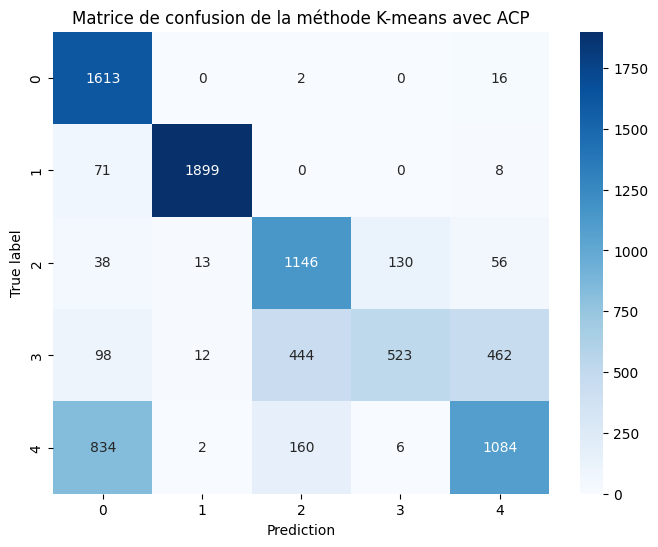

In [ ]:
# Classification K-means avec ACP

y_pred_KM = KMeans(n_clusters=5, init='random').fit_predict(Data_ACP)
y_pred_KM = correspondance(y_pred_KM,Label_ACP)

print('Partition retournée',y_pred_KM)

print('Score de performance :',accuracy_score(Label_ACP, y_pred_KM)*100, '%')

matrice = confusion_matrix(Label_ACP, y_pred_KM)

plt.figure(figsize=(8, 6))
sns.heatmap(matrice, annot=True, fmt='d', cmap='Blues')
plt.title('Matrice de confusion de la méthode K-means avec ACP')
plt.xlabel('Prediction')
plt.ylabel('True label')
plt.show()

Contrairement à l'Agglomerative Clustering, l'utilisation de l'ACP n'a pas permis d'améliorer le score du K-Means. On obtient une précision de 72.7%, ce qui est quasiment identique au résultat obtenu sur les données brutes.

Cela se confirme en regardant la matrice de confusion qui reste presque la même qu'avant. Les classes 0 et 1 sont bien isolées, mais les classes 2, 3 et 4 restent mal classées et mélangées entre elles.

Cela s'explique par le fonctionnement du K-Means : l'algo cherche absolument à former des groupes compacts et ronds. Même après avoir simplifié les données avec l'ACP, la forme des activités reste complexe et continue. Le K-Means n'arrive donc toujours pas à trouver la bonne frontière pour séparer ces activités trop proches.

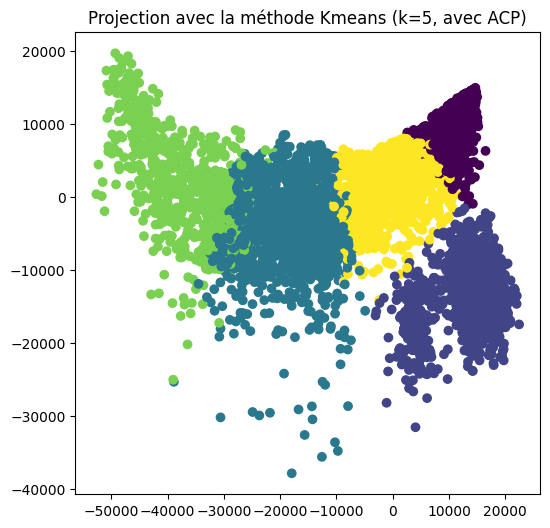

In [ ]:
plt.figure(figsize=(6, 6))
plt.scatter(Data_ACP[:, 0], Data_ACP[:, 1], c=y_pred_KM)
plt.title("Projection avec la méthode Kmeans (k=5, avec ACP)")
plt.show()

L'ACP a bien simplifié les données en ne gardant que l'essentiel et en éliminant le bruit inutile. On aurait pu penser que cela aiderait le K-Means à calculer de meilleures distances. Mais dans les faits, cela n'a pas suffi, même avec des données nettoyées.

Partition retournée [5. 4. 5. ... 5. 3. 3.]
Score de performance : 77.50957409771382 %


/tmp/ipython-input-3587745824.py:19: DeprecationWarning: Conversion of an array with ndim > 0 to a scalar is deprecated, and will error in future. Ensure you extract a single element from your array before performing this operation. (Deprecated NumPy 1.25.)
  number_labels[i] = reference_labels[y_pred[i]]


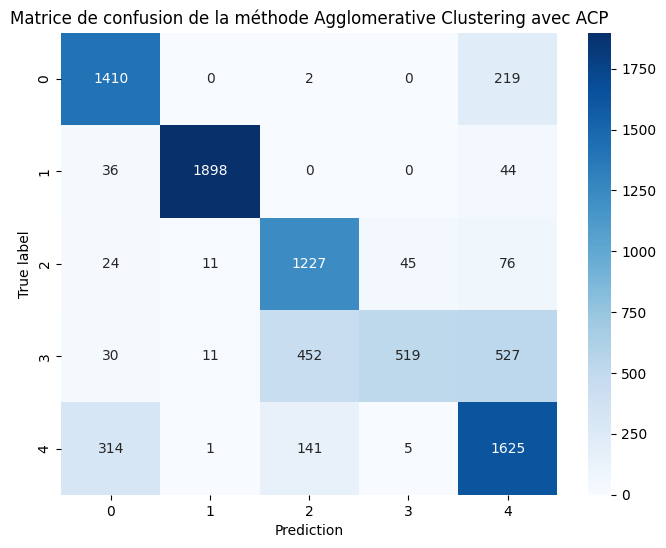

In [ ]:
# Agglomerative clustering avec ACP

clustering = AgglomerativeClustering(n_clusters=5)
y_pred_AC = clustering.fit_predict(Data_ACP)
y_pred_AC = correspondance(y_pred_AC,Label_ACP)

print('Partition retournée',y_pred_AC)

print('Score de performance :',accuracy_score(Label_ACP, y_pred_AC)*100, '%')

matrice = confusion_matrix(Label_ACP, y_pred_AC)

plt.figure(figsize=(8, 6))
sns.heatmap(matrice, annot=True, fmt='d', cmap='Blues')
plt.title('Matrice de confusion de la méthode Agglomerative Clustering avec ACP')
plt.xlabel('Prediction')
plt.ylabel('True label')
plt.show()

Avec un score de 77.5%, cette méthode obtient le meilleur résultat des approches non supervisées. Elle dépasse nettement le K-Means qui stagne autour de 72%.

Cela prouve que le nettoyage des données par l'ACP a été très efficace pour cette méthode qui fonctionne de proche en proche. En supprimant le bruit, l'algorithme arrive à former des groupes plus justes et cohérents.

L'analyse de la matrice montre les mêmes habitudes que pour les autres modèles. Les classes 0 et 1 sont bien identifiées, tandis que les classes 2, 3 et 4 restent mélangées car ce sont des activités plus complexes.

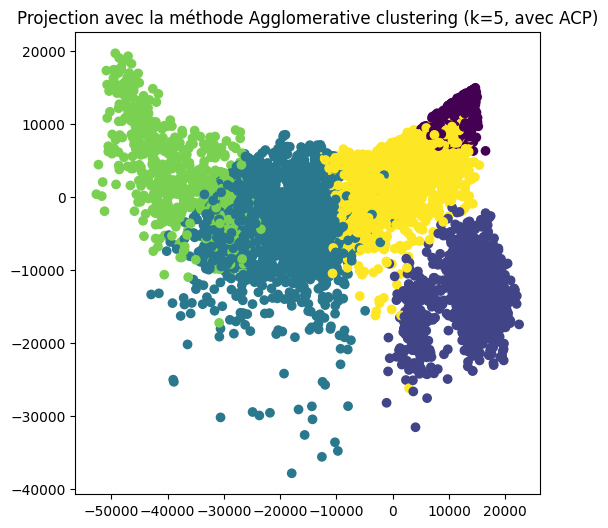

In [ ]:
plt.figure(figsize=(6, 6))
plt.scatter(Data_ACP[:, 0], Data_ACP[:, 1], c=y_pred_AC)
plt.title("Projection avec la méthode Agglomerative clustering (k=5, avec ACP)")
plt.show()

## Commentaires sur la méthode supervisée utilisée et les résultats suivant les capteurs:

L'utilisation de l'ACP entraîne une baisse de performance vraiment minime. La méthode Bayésienne passe de 85.5% à 85.2% et le KNN descend à peine de 87.4% à 87.2%. Perdre moins de 0.3% de précision est un résultat excellent quand on divise le nombre de variables par plus de 100 en passant de 468 à 3.

Cela prouve que les données calculées par TSFEL étaient déjà de très bonne qualité. L'ACP n'a pas inventé d'information nouvelle, mais elle a réussi à tout compresser sans rien perdre d'essentiel.

En conclusion, même si les scores baissent très légèrement, l'ACP reste une très bonne stratégie. Elle permet d'obtenir la même fiabilité que sur les données complètes, tout en ayant des modèles beaucoup plus légers et rapides à faire tourner.

# Bilan de l'analyse

Dans le cadre de ce projet, nous avons constaté que les méthodes supervisées sont clairement les plus efficaces. Avec un score de 87.4% pour le KNN, l'utilisation des étiquettes permet de séparer les activités avec une grande précision. En comparaison, les méthodes non supervisées restent en retrait car elles doivent deviner les groupes uniquement via la structure des données, sans connaître la vérité terrain.

L'apport de la réduction de dimension par ACP a été déterminant, mais de manière différente selon les approches. Pour les modèles supervisés, elle n'a pas augmenté le score car les données fournies par TSFEL étaient déjà d'excellente qualité. Cependant, elle a permis de compresser 468 variables en seulement 3. Cela rend les modèles beaucoup plus rapides et légers sans perdre en précision.

En revanche, pour le clustering, l'ACP a eu un impact visible surtout sur l'Agglomerative Clustering dont le score grimpe à 77.5%. En éliminant le bruit et la complexité inutile, l'ACP a aidé cet algorithme à mieux relier les points voisins. Le K-Means, lui, n'en a pas profité de la même façon.

En conclusion, la combinaison ACP + KNN représente le meilleur compromis pour ce projet. Elle offre la fiabilité maximale tout en garantissant une efficacité de calcul optimale.